In [150]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline

In [151]:
boston= pd.read_csv("HousingData.csv")

In [152]:
boston=boston.fillna(boston.median())

In [188]:
from sklearn.preprocessing import StandardScaler

In [196]:
x= boston.drop("MEDV", axis=1)
y= boston[["MEDV"]]

## Cross Validation Kfold

In [191]:
kf = KFold(shuffle=True, random_state=72018, n_splits=3) ##nsplit=3 means shape(x)/3

In [192]:
for train_index, test_index in kf.split(x_bc_trf):
    print("Train Index", train_index[:10], len(train_index))
    print("Test Index", test_index[:10], len(test_index))
    print("")

Train Index [ 1  3  4  5  7  8 10 11 12 13] 337
Test Index [ 0  2  6  9 15 17 19 23 25 26] 169

Train Index [ 0  2  6  9 10 11 12 13 15 17] 337
Test Index [ 1  3  4  5  7  8 14 16 22 27] 169

Train Index [0 1 2 3 4 5 6 7 8 9] 338
Test Index [10 11 12 13 18 20 21 24 28 31] 168



In [202]:
scores = []

lr = LinearRegression()

for train_index, test_index in kf.split(x):

    x_train = x.iloc[train_index]
    x_test = x.iloc[test_index]

    y_train = y.iloc[train_index]
    y_test = y.iloc[test_index]

    lr.fit(x_train, y_train)

    y_pred = lr.predict(x_test)

    score = r2_score(y_test, y_pred)

    scores.append(score)

print(scores)
print("Mean R²:", np.mean(scores))

[0.6627809975991654, 0.732909419452614, 0.7004155422285564]
Mean R²: 0.6987019864267786


In [203]:
scores = []

lr = LinearRegression()
scale = StandardScaler()
for train_index, test_index in kf.split(x):
    x_train, x_test, y_train, y_test  = (x.iloc[train_index],
                                        x.iloc[test_index],
                                        y.iloc[train_index],
                                        y.iloc[test_index])

    x_train_scaled= scale.fit_transform(x_train)
    x_test_scaled= scale.fit_transform(x_test)
    
    lr.fit(x_train_scaled, y_train)

    y_pred = lr.predict(x_test_scaled)

    score = r2_score(y_test, y_pred)

    scores.append(score)

print(scores)
print("Mean R²:", np.mean(scores))

[0.6669465441355069, 0.7395406526616406, 0.7104890289194339]
Mean R²: 0.7056587419055272


Normal
[0.6627809975991654, 0.732909419452614, 0.7004155422285564]
Mean R²: 0.6987019864267786

Scaled:
[0.6669465441355069, 0.7395406526616406, 0.7104890289194339]
Mean R²: 0.7056587419055272

## Pipeline and Cross_validation

In [204]:
lr = LinearRegression()
scale = StandardScaler()

pipeline= Pipeline([("scaler", scale),
                    ("regression", lr)])

In [207]:
prediction= cross_val_predict(pipeline, x,y, cv=kf)

In [210]:
r2_score(y, prediction)

0.6984003292035903

## Hyper Parameter Tuning and Lasso Regression

In [225]:
alphas= np.geomspace(float(1e-9), float(1e0), num=10)
alphas

array([1.e-09, 1.e-08, 1.e-07, 1.e-06, 1.e-05, 1.e-04, 1.e-03, 1.e-02,
       1.e-01, 1.e+00])

In [219]:
# #changing alpha 
# alphas= [0.001, 0.01, 0.1, 1.0, 10.0]

In [226]:
scores=[]
coef=[]
for alpha in alphas:
    las= Lasso(alpha=alpha, max_iter=100000)

    pipeline= Pipeline([(
              "Scale", scale),
              ("Lasso", las)
             ])

    predictions= cross_val_predict(pipeline, x, y, cv=kf)

    score= r2_score(y, predictions)
    scores.append(score)

In [227]:
list(zip(alphas ,scores))

[(np.float64(1e-09), 0.698400329306512),
 (np.float64(1e-08), 0.6984003302315727),
 (np.float64(1e-07), 0.6984003394997151),
 (np.float64(1e-06), 0.6984004319517966),
 (np.float64(1e-05), 0.6984013597278496),
 (np.float64(0.0001), 0.6984105825884361),
 (np.float64(0.001), 0.6985027369676772),
 (np.float64(0.01), 0.699343587860666),
 (np.float64(0.1), 0.6994075518777474),
 (np.float64(1.0), 0.6443896262290749)]

In [228]:
Lasso(alpha= 1e-6).fit(x,y).coef_

array([-1.07490516e-01,  4.01369381e-02, -3.74590745e-02,  3.07773519e+00,
       -1.67466897e+01,  4.06562035e+00, -8.29277250e-03, -1.46974713e+00,
        2.65246080e-01, -1.05419183e-02, -9.34383385e-01,  9.14661957e-03,
       -4.72560532e-01])

In [230]:
Lasso(alpha= 1.0).fit(x,y).coef_

array([-0.07197563,  0.04594707, -0.01381107,  0.        ,  0.        ,
        1.3891064 ,  0.00674842, -0.6877278 ,  0.23881917, -0.01482208,
       -0.70407504,  0.00800975, -0.68504439])

Text(0, 0.5, '$R^2')

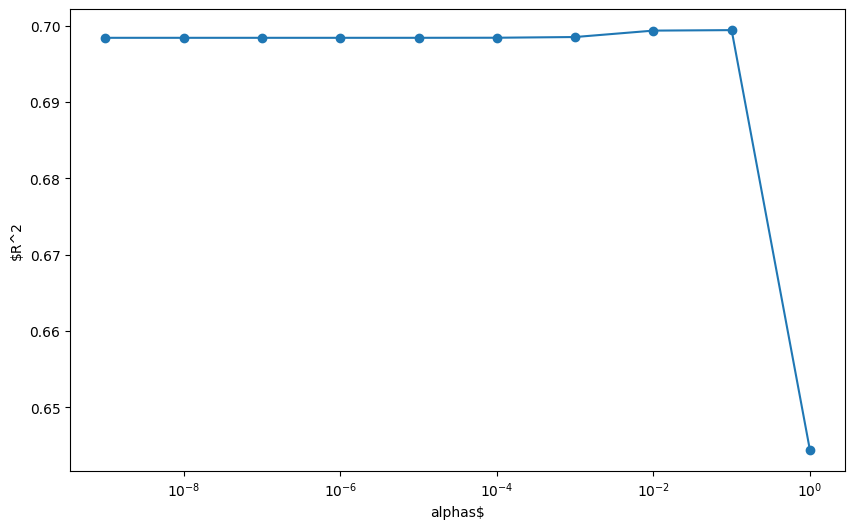

In [234]:
plt.figure(figsize=(10,6))
plt.semilogx(alphas, scores, "-o")
plt.xlabel("alphas$")
plt.ylabel("$R^2")

## Using Polynomial Features

In [248]:
pf= PolynomialFeatures(degree=3)
scores=[] 
alphas= np.geomspace(0.001, 10, 5)

for alpha in alphas:
    ls= Lasso(alpha=alpha, max_iter=100000)
    pipeline= Pipeline([("Make-Higher-Degree", pf),
                        ("Scale", scale),
                        ("Lasso-Regression", ls)
                        ])

    predictions= cross_val_predict(pipeline, x,y, cv=kf)

    score= r2_score(predictions, y)
    scores.append(score)

C:\Users\gameg\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.654e+01, tolerance: 2.735e+00
  model = cd_fast.enet_coordinate_descent(
C:\Users\gameg\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.810e+01, tolerance: 2.777e+00
  model = cd_fast.enet_coordinate_descent(
C:\Users\gameg\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.882e+01, toleranc

In [249]:
alphas

array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01])

In [250]:
scores

[0.7037554716325317,
 0.8369592641421941,
 0.7663776844933843,
 0.48951275115170956,
 -8135.039968660309]

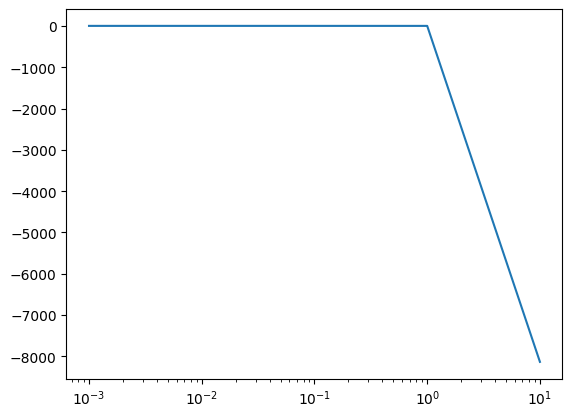

In [251]:
plt.semilogx(alphas, scores)

In [254]:
best_estimator = Pipeline([("make-higher-degree", PolynomialFeatures(degree=2)),
                           ("scaler", scale),
                           ("Lasso-Regression", Lasso(alpha= 0.01, max_iter=100000))
                          ])

best_estimator.fit(x,y)
best_estimator.score(x,y)

0.8936753972861596

## Ridge Regression Testing

In [255]:
pf= PolynomialFeatures(degree=2)
scores=[] 
alphas= np.geomspace(0.1, 2, 20)

for alpha in alphas:
    ridge= Ridge(alpha=alpha, max_iter=100000)
    pipeline= Pipeline([("Make-Higher-Degree", pf),
                        ("Scale", scale),
                        ("Ridge-Regression", ridge)
                        ])

    predictions= cross_val_predict(pipeline, x,y, cv=kf)

    score= r2_score(predictions, y)
    scores.append(score)

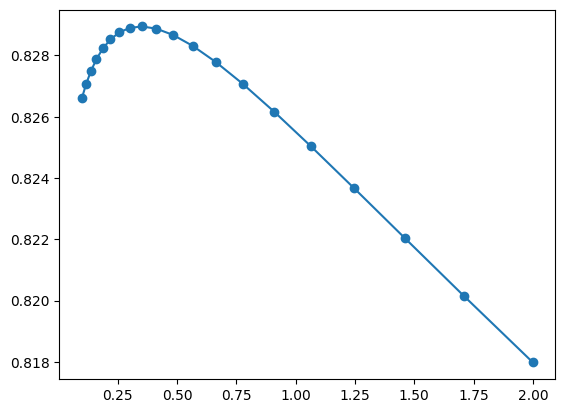

In [258]:
plt.plot(alphas, scores, "-o")

## Lasso Regression Optimal

In [259]:
best_estimator = Pipeline([("make-higher-degree", PolynomialFeatures(degree=2)),
                           ("scaler", scale),
                           ("Lasso-Regression", Lasso(alpha= 0.01, max_iter=100000))
                          ])

best_estimator.fit(x,y)
best_estimator.score(x,y)

0.8936753972861596

In [281]:
dfimportance= pd.DataFrame(zip(best_estimator.named_steps['make-higher-degree'].get_feature_names_out(input_features=x.columns),
                           best_estimator.named_steps['Lasso-Regression'].coef_))


In [290]:
dfimportance.sort_values(by=1, ascending=False)

,0,1
9,RAD,11.453587
69,RM^2,8.544850
96,TAX PTRATIO,7.548434
4,CHAS,7.266518
104,LSTAT^2,5.432879
...,...,...
72,RM RAD,-4.252088
49,INDUS LSTAT,-4.892448
52,CHAS RM,-6.108196
8,DIS,-7.114787


## Grid Search CV

In [291]:
from sklearn.model_selection import GridSearchCV

In [303]:
estimator = Pipeline([
    ("polynomial-features", PolynomialFeatures()),
    ("scale", StandardScaler()),
    ("ridge_regression", Ridge())
])

params = {
    "polynomial-features__degree": [1, 2, 3], ##__ is important after the name
    "ridge_regression__alpha": np.geomspace(4, 20, 30)
}

grid = GridSearchCV(
    estimator,
    params,
    cv=kf
)

grid.fit(x, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...n', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'polynomial-features__degree': [1, 2, ...], 'ridge_regression__alpha': array([ 4. ... 20. ])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and param

In [305]:
grid.best_score_, grid.best_params_

(np.float64(0.8414447839845643),
 {'polynomial-features__degree': 3,
  'ridge_regression__alpha': np.float64(6.591461455321584)})

In [306]:
y_pred= grid.predict(x)

In [307]:
r2_score(y, y_pred)

0.9213277016603648

In [308]:
pd.DataFrame(grid.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_polynomial-features__degree,param_ridge_regression__alpha,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.005591,0.001200,0.002373,0.000504,1,4.000000,"{'polynomial-features__degree': 1, 'ridge_regr...",0.663114,0.733351,0.704883,0.700449,0.028845,90
1,0.004245,0.000027,0.002016,0.000129,1,4.228267,"{'polynomial-features__degree': 1, 'ridge_regr...",0.663119,0.733363,0.705084,0.700522,0.028858,89
2,0.004472,0.000290,0.002108,0.000284,1,4.469560,"{'polynomial-features__degree': 1, 'ridge_regr...",0.663123,0.733374,0.705291,0.700596,0.028872,88
3,0.004343,0.000194,0.002110,0.000238,1,4.724624,"{'polynomial-features__degree': 1, 'ridge_regr...",0.663126,0.733385,0.705505,0.700672,0.028886,87
4,0.004813,0.000429,0.002198,0.000255,1,4.994243,"{'polynomial-features__degree': 1, 'ridge_regr...",0.663127,0.733395,0.705724,0.700749,0.028901,86
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,0.011360,0.001267,0.003163,0.000281,3,16.018444,"{'polynomial-features__degree': 3, 'ridge_regr...",0.800879,0.848775,0.865305,0.838320,0.027321,26
86,0.011280,0.001290,0.002803,0.000339,3,16.932565,"{'polynomial-features__degree': 3, 'ridge_regr...",0.800490,0.848375,0.864866,0.837910,0.027303,27
87,0.009496,0.000195,0.002909,0.000387,3,17.898852,"{'polynomial-features__degree': 3, 'ridge_regr...",0.800085,0.847953,0.864386,0.837475,0.027277,28
88,0.011508,0.001541,0.002943,0.000345,3,18.920281,"{'polynomial-features__degree': 3, 'ridge_regr...",0.799664,0.847510,0.863863,0.837012,0.027240,29
